# CENG313 - Assignment 1: EDA and Baseline Models

**Competition:** MABe Challenge - Social Action Recognition in Mice

**Group:** GROUP19 (Medium)

**Members:** Efe Zeybek, Aytuğ Güler

## Objective
This notebook explores the MABe mouse behavior dataset, analyzes its structure and distributions, and develops baseline models for social behavior recognition.


In [2]:

%pip install -q kagglehub pandas numpy matplotlib seaborn scikit-learn pyarrow


In [3]:

import os
from pathlib import Path

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import f1_score, precision_score, recall_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("Environment setup completed successfully!")
print("Pandas version:", pd.__version__)


Environment setup completed successfully!
Pandas version: 2.2.3


In [4]:

data_dir = Path(
    kagglehub.competition_download(
        "MABe-mouse-behavior-detection"
    )
)

print("Dataset directory:", data_dir)
print("\nFiles and folders:")

for item in data_dir.iterdir():
    print("-", item.name)


100%|██████████| 2.63G/2.63G [00:46<00:00, 60.9MB/s]

Extracting files...


Dataset directory: /root/.cache/kagglehub/competitions/MABe-mouse-behavior-detection

Files and folders:
- train.csv
- test_tracking
- train_annotation
- train_tracking
- sample_submission.csv
- test.csv


## 1. Exploratory Data Analysis (EDA)

In this section, we explore the structure, metadata, and characteristics of the MABe dataset before developing baseline models.

In [5]:

# Load training and test metadata

train = pd.read_csv(data_dir / "train.csv")
test = pd.read_csv(data_dir / "test.csv")

print("Training dataset shape:", train.shape)
print("Test dataset shape:", test.shape)

print("\nTraining columns:")
print(train.columns.tolist())

print("\nFirst five training records:")
display(train.head())

print("\nFirst five test records:")
display(test.head())


Training dataset shape: (8789, 38)
Test dataset shape: (1, 38)

Training columns:
['lab_id', 'video_id', 'mouse1_strain', 'mouse1_color', 'mouse1_sex', 'mouse1_id', 'mouse1_age', 'mouse1_condition', 'mouse2_strain', 'mouse2_color', 'mouse2_sex', 'mouse2_id', 'mouse2_age', 'mouse2_condition', 'mouse3_strain', 'mouse3_color', 'mouse3_sex', 'mouse3_id', 'mouse3_age', 'mouse3_condition', 'mouse4_strain', 'mouse4_color', 'mouse4_sex', 'mouse4_id', 'mouse4_age', 'mouse4_condition', 'frames_per_second', 'video_duration_sec', 'pix_per_cm_approx', 'video_width_pix', 'video_height_pix', 'arena_width_cm', 'arena_height_cm', 'arena_shape', 'arena_type', 'body_parts_tracked', 'behaviors_labeled', 'tracking_method']

First five training records:


,lab_id,video_id,mouse1_strain,mouse1_color,mouse1_sex,mouse1_id,mouse1_age,mouse1_condition,mouse2_strain,mouse2_color,...,pix_per_cm_approx,video_width_pix,video_height_pix,arena_width_cm,arena_height_cm,arena_shape,arena_type,body_parts_tracked,behaviors_labeled,tracking_method
0,AdaptableSnail,44566106,CD-1 (ICR),white,male,10.0,8-12 weeks,wireless device,CD-1 (ICR),white,...,16.0,1228,1068,60.0,60.0,square,familiar,"[""body_center"", ""ear_left"", ""ear_right"", ""head...","[""mouse1,mouse2,approach"", ""mouse1,mouse2,atta...",DeepLabCut
1,AdaptableSnail,143861384,CD-1 (ICR),white,male,3.0,8-12 weeks,NaN,CD-1 (ICR),white,...,9.7,968,608,60.0,60.0,square,familiar,"[""body_center"", ""ear_left"", ""ear_right"", ""late...","[""mouse1,mouse2,approach"", ""mouse1,mouse2,atta...",DeepLabCut
2,AdaptableSnail,209576908,CD-1 (ICR),white,male,7.0,8-12 weeks,NaN,CD-1 (ICR),white,...,16.0,1266,1100,60.0,60.0,square,familiar,"[""body_center"", ""ear_left"", ""ear_right"", ""late...","[""mouse1,mouse2,approach"", ""mouse1,mouse2,atta...",DeepLabCut
3,AdaptableSnail,278643799,CD-1 (ICR),white,male,11.0,8-12 weeks,wireless device,CD-1 (ICR),white,...,16.0,1224,1100,60.0,60.0,square,familiar,"[""body_center"", ""ear_left"", ""ear_right"", ""head...","[""mouse1,mouse2,approach"", ""mouse1,mouse2,atta...",DeepLabCut
4,AdaptableSnail,351967631,CD-1 (ICR),white,male,14.0,8-12 weeks,NaN,CD-1 (ICR),white,...,16.0,1204,1068,60.0,60.0,square,familiar,"[""body_center"", ""ear_left"", ""ear_right"", ""late...","[""mouse1,mouse2,approach"", ""mouse1,mouse2,atta...",DeepLabCut



First five test records:


,lab_id,video_id,mouse1_strain,mouse1_color,mouse1_sex,mouse1_id,mouse1_age,mouse1_condition,mouse2_strain,mouse2_color,...,pix_per_cm_approx,video_width_pix,video_height_pix,arena_width_cm,arena_height_cm,arena_shape,arena_type,body_parts_tracked,behaviors_labeled,tracking_method
0,AdaptableSnail,438887472,CD-1 (ICR),white,male,13.0,8-12 weeks,wireless device,CD-1 (ICR),white,...,16.0,1214,1090,60.0,60.0,square,familiar,"[""body_center"", ""ear_left"", ""ear_right"", ""head...","[""mouse1,mouse2,approach"", ""mouse1,mouse2,atta...",DeepLabCut


In [6]:

# Inspect tracking and annotation files

tracking_files = sorted(
    (data_dir / "train_tracking").rglob("*.parquet")
)

annotation_files = sorted(
    (data_dir / "train_annotation").rglob("*.parquet")
)

test_tracking_files = sorted(
    (data_dir / "test_tracking").rglob("*.parquet")
)

print("Training tracking files:", len(tracking_files))
print("Training annotation files:", len(annotation_files))
print("Test tracking files:", len(test_tracking_files))

if tracking_files:
    print("\nExample tracking file:")
    print(tracking_files[0])

if annotation_files:
    print("\nExample annotation file:")
    print(annotation_files[0])


Training tracking files: 8789
Training annotation files: 847
Test tracking files: 1

Example tracking file:
/root/.cache/kagglehub/competitions/MABe-mouse-behavior-detection/train_tracking/AdaptableSnail/1212811043.parquet

Example annotation file:
/root/.cache/kagglehub/competitions/MABe-mouse-behavior-detection/train_annotation/AdaptableSnail/1212811043.parquet


### 1.1 Dataset Overview and Data Quality

We analyze the training metadata to understand the dataset structure, missing values, laboratory distributions, and video characteristics.

In [7]:

# Dataset overview and basic statistics

print("Training videos:", len(train))
print("Test videos:", len(test))
print("Number of columns:", train.shape[1])

print("\nColumn data types:")
display(train.dtypes.to_frame("Data type"))

print("\nNumeric summary:")
display(train.describe().T)

print("\nNumber of laboratories:", train["lab_id"].nunique())

print("\nLaboratory distribution:")
display(train["lab_id"].value_counts())


Training videos: 8789
Test videos: 1
Number of columns: 38

Column data types:


,Data type
lab_id,object
video_id,int64
mouse1_strain,object
mouse1_color,object
mouse1_sex,object
mouse1_id,float64
mouse1_age,object
mouse1_condition,object
mouse2_strain,object
mouse2_color,object



Numeric summary:


,count,mean,std,min,25%,50%,75%,max
video_id,8789.0,1.072697e+09,6.209820e+08,9603.0,5.380940e+08,1.072003e+09,1.615401e+09,2.147479e+09
mouse1_id,816.0,2.457108e+01,2.244420e+01,1.0,6.000000e+00,1.500000e+01,3.800000e+01,8.000000e+01
mouse2_id,108.0,1.951852e+01,1.166069e+01,1.0,1.200000e+01,1.700000e+01,2.425000e+01,5.300000e+01
mouse3_id,17.0,3.558824e+01,4.542285e+00,29.0,3.200000e+01,3.500000e+01,3.900000e+01,4.200000e+01
mouse4_id,10.0,4.840000e+01,2.951459e+00,44.0,4.625000e+01,4.800000e+01,5.100000e+01,5.200000e+01
frames_per_second,8789.0,3.040265e+01,6.434061e+00,10.0,3.000000e+01,3.000000e+01,3.000000e+01,1.200200e+02
video_duration_sec,8789.0,1.346479e+02,6.371238e+02,19.0,6.000000e+01,6.000000e+01,6.000000e+01,1.980100e+04
pix_per_cm_approx,8789.0,1.244019e+01,3.405194e+00,5.5,1.170000e+01,1.170000e+01,1.170000e+01,6.500000e+01
video_width_pix,8789.0,8.136542e+02,1.094109e+02,300.0,8.000000e+02,8.000000e+02,8.000000e+02,2.048000e+03
video_height_pix,8789.0,7.903697e+02,1.338698e+02,194.0,8.000000e+02,8.000000e+02,8.000000e+02,2.056000e+03



Number of laboratories: 21

Laboratory distribution:


,count
lab_id,
MABe22_keypoints,5320
MABe22_movies,2606
CalMS21_supplemental,297
CalMS21_task1,101
CalMS21_task2,76
SparklingTapir,69
JovialSwallow,52
PleasantMeerkat,36
InvincibleJellyfish,33


,Missing Count,Missing Percentage
mouse4_condition,8786,99.965866
mouse4_color,8779,99.886221
mouse4_strain,8779,99.886221
mouse4_sex,8779,99.886221
mouse4_id,8779,99.886221
mouse4_age,8778,99.874844
mouse3_id,8772,99.806576
mouse2_id,8681,98.771191
mouse1_id,7973,90.715667
behaviors_labeled,7941,90.351576


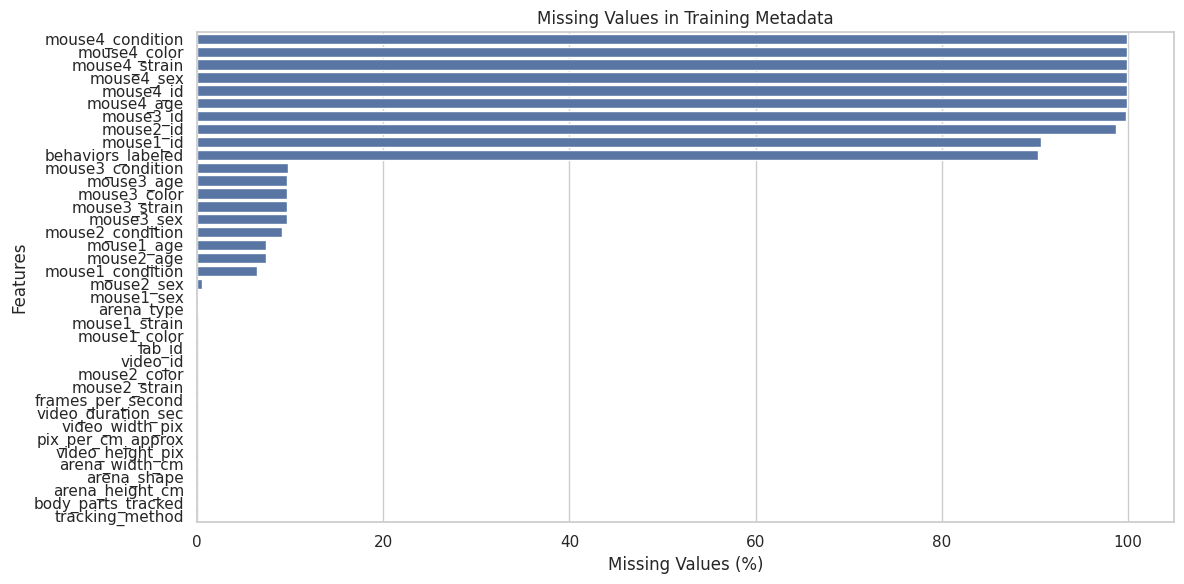

In [8]:

# Missing values analysis

missing_count = train.isnull().sum()

missing_percentage = (
    train.isnull().mean() * 100
)

missing_df = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
}).sort_values(
    "Missing Percentage",
    ascending=False
)

display(missing_df)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=missing_df.reset_index(),
    x="Missing Percentage",
    y="index"
)

plt.title("Missing Values in Training Metadata")
plt.xlabel("Missing Values (%)")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


### Missing Values – Findings

The dataset contains substantial missing values in mouse identification fields and behavior annotation metadata. For example, `mouse1_id` is missing in approximately 90.72% of the training records, while `behaviors_labeled` is missing in approximately 90.35%.

However, important numerical metadata such as frame rate, video duration, and arena dimensions are complete. Missing metadata values should not automatically be replaced with zero, since some fields may be unavailable or not applicable to certain recordings.

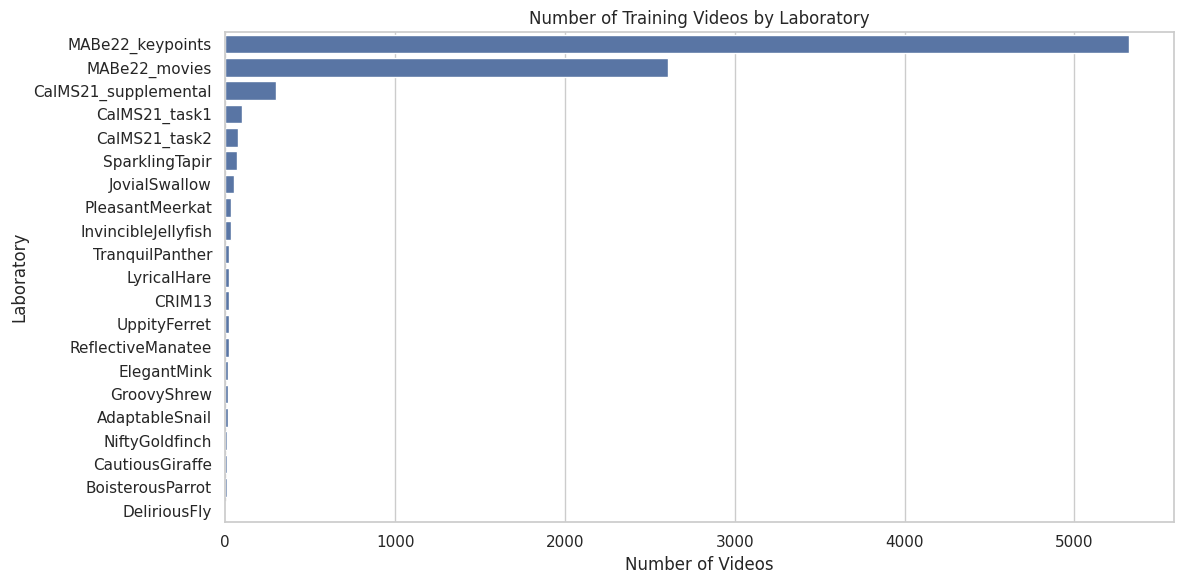

Total laboratories: 21
Largest laboratory: MABe22_keypoints
Videos in largest laboratory: 5320


In [9]:

# Laboratory distribution

lab_counts = train["lab_id"].value_counts()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=lab_counts.values,
    y=lab_counts.index
)

plt.title("Number of Training Videos by Laboratory")
plt.xlabel("Number of Videos")
plt.ylabel("Laboratory")
plt.tight_layout()
plt.show()

print("Total laboratories:", len(lab_counts))
print("Largest laboratory:", lab_counts.index[0])
print("Videos in largest laboratory:", lab_counts.iloc[0])


### Laboratory Distribution – Findings

The training dataset contains videos from 21 laboratories. However, the distribution is highly imbalanced. MABe22_keypoints contributes 5,320 videos (60.5%), while MABe22_movies contributes 2,606 videos (29.7%). Together, these two sources account for approximately 90.2% of the training videos.

This imbalance should be considered when selecting training and validation data, as a model trained predominantly on these sources may not generalize well to smaller laboratories.

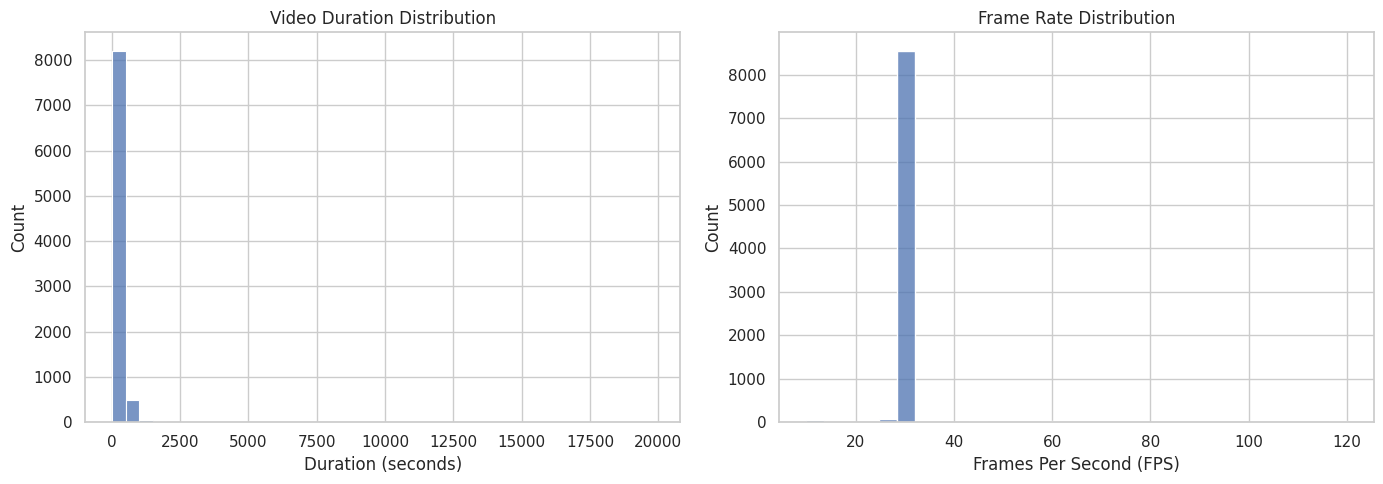

Average duration: 134.6478552736375
Average FPS: 30.402647627716462


In [10]:

# Video duration and frame rate distributions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=train,
    x="video_duration_sec",
    bins=40,
    ax=axes[0]
)

axes[0].set_title("Video Duration Distribution")
axes[0].set_xlabel("Duration (seconds)")

sns.histplot(
    data=train,
    x="frames_per_second",
    bins=30,
    ax=axes[1]
)

axes[1].set_title("Frame Rate Distribution")
axes[1].set_xlabel("Frames Per Second (FPS)")

plt.tight_layout()
plt.show()

print("Average duration:", train["video_duration_sec"].mean())
print("Average FPS:", train["frames_per_second"].mean())


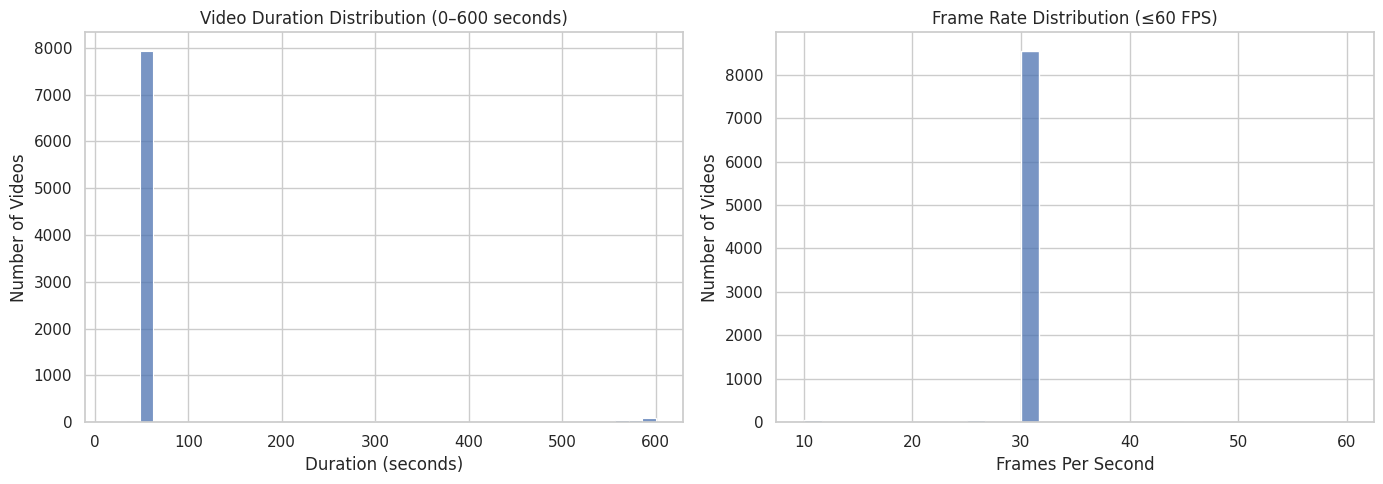

Videos longer than 600 seconds: 404
Videos above 60 FPS: 43


In [11]:

# Improved video duration and FPS distributions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Focus on typical video durations
sns.histplot(
    train.loc[
        train["video_duration_sec"] <= 600,
        "video_duration_sec"
    ],
    bins=40,
    ax=axes[0]
)

axes[0].set_title("Video Duration Distribution (0–600 seconds)")
axes[0].set_xlabel("Duration (seconds)")
axes[0].set_ylabel("Number of Videos")

# Focus on common frame rates
sns.histplot(
    train.loc[
        train["frames_per_second"] <= 60,
        "frames_per_second"
    ],
    bins=30,
    ax=axes[1]
)

axes[1].set_title("Frame Rate Distribution (≤60 FPS)")
axes[1].set_xlabel("Frames Per Second")
axes[1].set_ylabel("Number of Videos")

plt.tight_layout()
plt.show()

print(
    "Videos longer than 600 seconds:",
    (train["video_duration_sec"] > 600).sum()
)

print(
    "Videos above 60 FPS:",
    (train["frames_per_second"] > 60).sum()
)


### Video Duration and Frame Rate – Findings

The average video duration is approximately 134.65 seconds, while the median duration is 60 seconds. The dataset includes 404 videos longer than 600 seconds, indicating substantial variation in recording length.

The average frame rate is approximately 30.40 FPS, with a median of 30 FPS. Only 43 videos have frame rates above 60 FPS.

These differences are relevant for feature extraction and computational efficiency. Motion-related features should account for frame rate differences to ensure comparability across recordings.

### 1.2 Tracking and Behavior Annotation Analysis

This section examines mouse tracking coordinates and annotated behavior intervals to understand the structure of the prediction task.

In [12]:

# Inspect one labeled video and its tracking data

annotation_path = annotation_files[0]

tracking_path = (
    data_dir
    / "train_tracking"
    / annotation_path.parent.name
    / annotation_path.name
)

annotation_example = pd.read_parquet(annotation_path)
tracking_example = pd.read_parquet(tracking_path)

print("ANNOTATION DATA")
print("File:", annotation_path)
print("Shape:", annotation_example.shape)
print("Columns:", annotation_example.columns.tolist())

display(annotation_example.head(10))

print("\nTRACKING DATA")
print("File:", tracking_path)
print("Shape:", tracking_example.shape)
print("Columns:", tracking_example.columns.tolist())

display(tracking_example.head(10))


ANNOTATION DATA
File: /root/.cache/kagglehub/competitions/MABe-mouse-behavior-detection/train_annotation/AdaptableSnail/1212811043.parquet
Shape: (370, 5)
Columns: ['agent_id', 'target_id', 'action', 'start_frame', 'stop_frame']


,agent_id,target_id,action,start_frame,stop_frame
0,1,3,chase,2,54
1,1,3,chase,128,234
2,3,2,avoid,324,342
3,3,1,avoid,324,342
4,1,2,chase,942,1052
5,4,3,chase,1205,1276
6,4,3,chase,1313,1370
7,1,2,chase,1416,1458
8,4,3,chase,1819,1908
9,4,2,chase,2041,2101



TRACKING DATA
File: /root/.cache/kagglehub/competitions/MABe-mouse-behavior-detection/train_tracking/AdaptableSnail/1212811043.parquet
Shape: (2677006, 5)
Columns: ['video_frame', 'mouse_id', 'bodypart', 'x', 'y']


,video_frame,mouse_id,bodypart,x,y
0,0,1,body_center,496.187012,376.475006
1,0,1,ear_left,494.059998,343.924011
2,0,1,ear_right,518.765015,367.362000
3,0,1,lateral_left,474.536987,370.563995
4,0,1,lateral_right,505.825012,394.937012
5,0,1,nose,527.765015,342.686005
6,0,1,tail_base,477.536011,398.338013
7,0,1,tail_midpoint,446.834015,429.035004
8,0,1,tail_tip,424.618011,457.161011
9,0,2,body_center,702.916016,322.872986


### 1.3 Behavior Annotation Distribution

We analyze the frequency and duration of annotated behavior events across the training dataset to identify class imbalance and inform baseline model selection.

In [13]:

# Aggregate behavior annotations across all labeled videos

from collections import Counter

action_counts = Counter()
action_durations = Counter()
annotated_video_counts = Counter()

total_events = 0

for path in annotation_files:
    df = pd.read_parquet(
        path,
        columns=["action", "start_frame", "stop_frame"]
    )

    # Count annotated behavior events
    counts = df["action"].value_counts()
    action_counts.update(counts.to_dict())

    # Count annotated frames per behavior event
    durations = (
        df["stop_frame"] - df["start_frame"]
    )

    duration_by_action = durations.groupby(
        df["action"]
    ).sum()

    action_durations.update(duration_by_action.to_dict())

    # Number of videos containing each action
    annotated_video_counts.update(
        df["action"].dropna().unique()
    )

    total_events += len(df)

behavior_summary = pd.DataFrame({
    "Action": list(action_counts.keys()),
    "Event Count": [
        action_counts[a] for a in action_counts
    ],
    "Annotated Frames": [
        action_durations[a] for a in action_counts
    ],
    "Videos": [
        annotated_video_counts[a] for a in action_counts
    ]
}).sort_values(
    "Event Count",
    ascending=False
).reset_index(drop=True)

print("Annotation files:", len(annotation_files))
print("Total annotated events:", total_events)
print("Unique behaviors:", len(action_counts))

display(behavior_summary.head(30))


Annotation files: 847
Total annotated events: 83620
Unique behaviors: 37


,Action,Event Count,Annotated Frames,Videos
0,sniff,37837,2150590,594
1,sniffgenital,7862,703931,405
2,attack,7462,518870,332
3,rear,4408,230889,85
4,sniffbody,3518,103274,109
5,approach,3270,85968,159
6,sniffface,2811,71527,108
7,mount,2747,284931,247
8,escape,2071,90304,93
9,reciprocalsniff,1492,40682,21


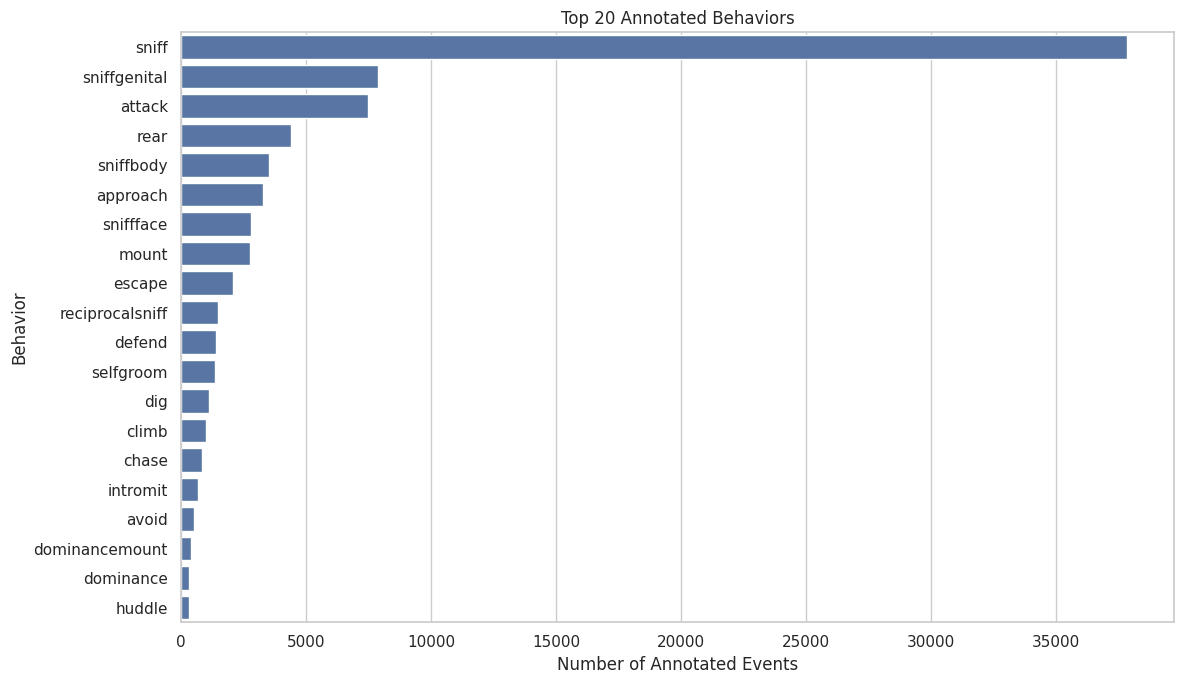

In [14]:

# Visualize the most frequent behaviors

top_actions = behavior_summary.head(20)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_actions,
    x="Event Count",
    y="Action"
)

plt.title("Top 20 Annotated Behaviors")
plt.xlabel("Number of Annotated Events")
plt.ylabel("Behavior")

plt.tight_layout()
plt.show()


### Behavior Distribution – Findings

The training annotation data contains 83,620 labeled behavior events across 847 annotation files, representing 37 distinct behavior categories.

The most frequent behavior is `sniff`, with 37,837 events, accounting for approximately 45.2% of all annotated events. Other frequently observed behaviors include `sniffgenital`, `attack`, and `rear`.

This distribution reveals substantial class imbalance. Therefore, baseline models should be evaluated using appropriate metrics, such as precision, recall, and F1-score, rather than relying on accuracy alone.

Additionally, behavior annotation coverage varies across videos and laboratories, which must be considered when constructing training and validation datasets.


### 1.4 Tracking Data Exploration

This section examines the structure of mouse tracking data, including tracked body parts, mouse identifiers, frame counts, and missing coordinates. Understanding these characteristics is important before extracting motion-related features for baseline models.

In [15]:

# Inspect available body parts and mouse IDs

print("Tracked body parts:")
print(tracking_example["bodypart"].unique())

print("\nMouse IDs:")
print(tracking_example["mouse_id"].unique())

print("\nTotal unique frames:")
print(tracking_example["video_frame"].nunique())

print("\nMissing coordinate values:")
print(tracking_example[["x", "y"]].isnull().sum())


Tracked body parts:
['body_center' 'ear_left' 'ear_right' 'lateral_left' 'lateral_right'
 'nose' 'tail_base' 'tail_midpoint' 'tail_tip' 'neck']

Mouse IDs:
[1 2 3 4]

Total unique frames:
89966

Missing coordinate values:
x    0
y    0
dtype: int64


### Mouse Movement Trajectory

We visualize the movement trajectory of a selected mouse using its body center coordinates. The first 1,500 available observations are used to illustrate the mouse's movement path without displaying the entire recording.

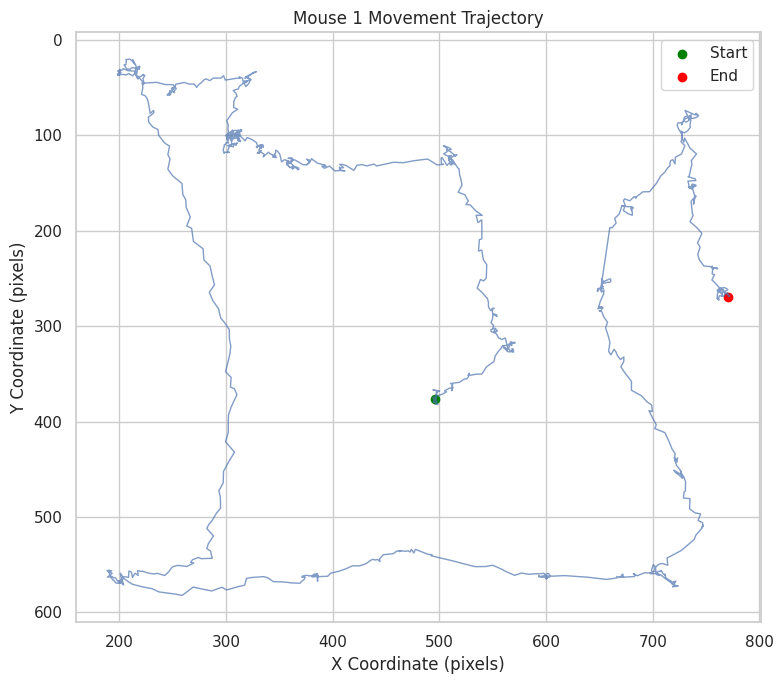

In [16]:

# Visualize mouse movement trajectory

mouse_id = tracking_example["mouse_id"].unique()[0]

mouse_center = tracking_example[
    (tracking_example["mouse_id"] == mouse_id) &
    (tracking_example["bodypart"] == "body_center")
].sort_values("video_frame")

# Plot a limited segment for clarity
mouse_sample = mouse_center.head(1500)

plt.figure(figsize=(8, 7))

plt.plot(
    mouse_sample["x"],
    mouse_sample["y"],
    linewidth=1,
    alpha=0.7
)

plt.scatter(
    mouse_sample["x"].iloc[0],
    mouse_sample["y"].iloc[0],
    color="green",
    label="Start"
)

plt.scatter(
    mouse_sample["x"].iloc[-1],
    mouse_sample["y"].iloc[-1],
    color="red",
    label="End"
)

plt.title(f"Mouse {mouse_id} Movement Trajectory")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.gca().invert_yaxis()
plt.legend()
plt.tight_layout()
plt.show()


### Tracking Data – Findings

The inspected tracking file contains four mice, ten tracked body parts, and 89,966 unique video frames. No missing X or Y coordinate values were detected in the available tracking records.

The movement trajectory of Mouse 1 was visualized using its first 1,500 body-center observations. The plot shows movement across different regions of the arena, including paths near its boundaries.

These tracking coordinates can be used to calculate movement-related features, such as speed, displacement, and distances between mice. However, trajectory visualization alone is not sufficient to identify specific social behaviors.



### Inter-Mouse Distance Analysis

We calculate the distance between the body centers of two mice over time. This analysis illustrates how spatial relationships between mice can be represented as numerical features for behavior recognition.


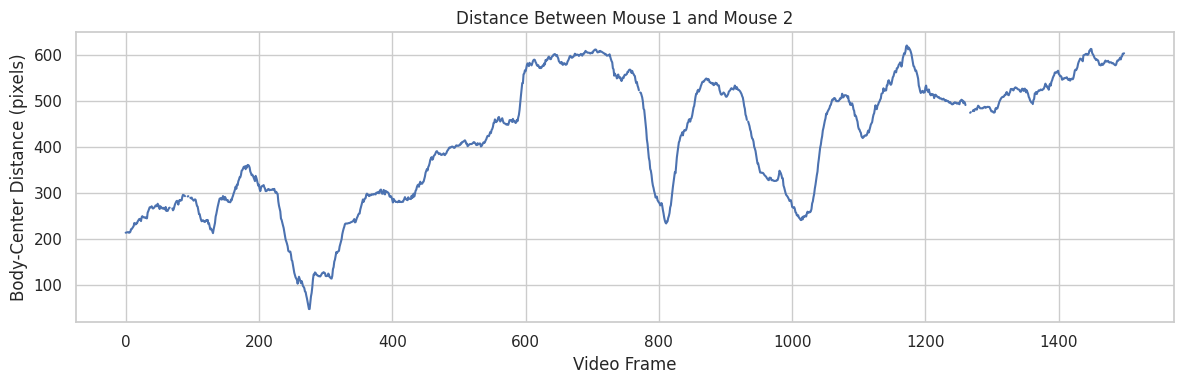

Average distance (pixels): 415.36353
Minimum distance (pixels): 47.24904251098633
Maximum distance (pixels): 621.0775756835938


In [17]:

# Calculate distance between Mouse 1 and Mouse 2

centers = tracking_example[
    (tracking_example["bodypart"] == "body_center") &
    (tracking_example["mouse_id"].isin([1, 2]))
]

center_positions = centers.pivot_table(
    index="video_frame",
    columns="mouse_id",
    values=["x", "y"],
    aggfunc="first"
)

dx = center_positions[("x", 1)] - center_positions[("x", 2)]
dy = center_positions[("y", 1)] - center_positions[("y", 2)]

distance_pixels = np.sqrt(dx**2 + dy**2)

# Use the first 1500 frames
distance_sample = distance_pixels.iloc[:1500]

plt.figure(figsize=(12, 4))
plt.plot(
    distance_sample.index,
    distance_sample.values
)

plt.title("Distance Between Mouse 1 and Mouse 2")
plt.xlabel("Video Frame")
plt.ylabel("Body-Center Distance (pixels)")
plt.tight_layout()
plt.show()

print("Average distance (pixels):", distance_sample.mean())
print("Minimum distance (pixels):", distance_sample.min())
print("Maximum distance (pixels):", distance_sample.max())


### Inter-Mouse Distance – Findings

The body-center distance between Mouse 1 and Mouse 2 was analyzed over the first 1,500 frames. The average distance was approximately 415.36 pixels, with a minimum of 47.25 pixels and a maximum of 621.08 pixels.

The distance varies substantially over time, indicating periods when the mice move closer together or farther apart. Such spatial features may be useful for recognizing social behaviors, but distance alone is insufficient to determine the actual behavior.

Therefore, the tracking measurements must be compared with annotated behavior intervals before drawing behavioral conclusions.

### Tracking and Annotation Alignment

We examine a labeled social behavior event and compare its annotated time interval with the corresponding inter-mouse distance. This helps verify how behavioral labels align with tracking coordinates and demonstrates the relationship between spatial features and annotated actions.

Behavior: chase
Agent: 1 Target: 3
Annotated interval: 2 54


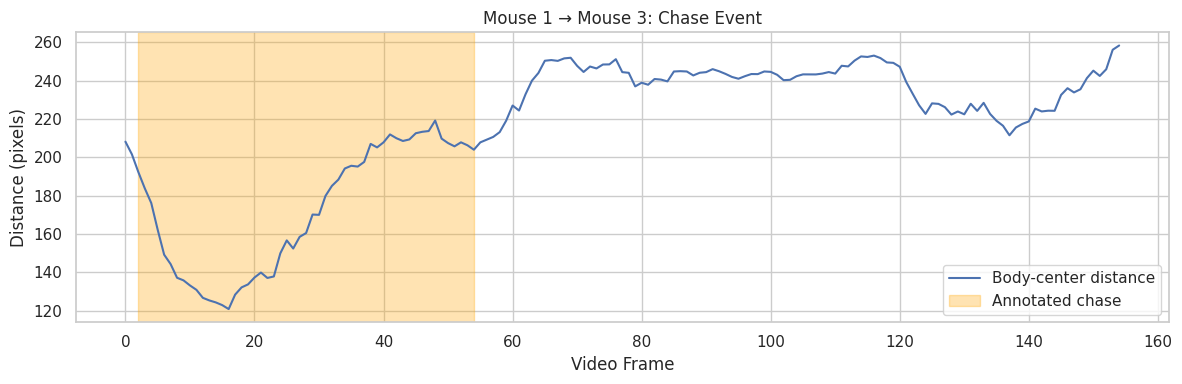

In [18]:

# Compare a labeled chase event with tracking distance

chase_events = annotation_example[
    (annotation_example["action"] == "chase") &
    (annotation_example["agent_id"] != annotation_example["target_id"])
]

event = chase_events.iloc[0]

agent = int(event["agent_id"])
target = int(event["target_id"])

start = int(event["start_frame"])
stop = int(event["stop_frame"])

print("Behavior:", event["action"])
print("Agent:", agent, "Target:", target)
print("Annotated interval:", start, stop)

# Select relevant body-center coordinates
pair_tracking = tracking_example[
    (tracking_example["bodypart"] == "body_center") &
    (tracking_example["mouse_id"].isin([agent, target]))
]

positions = pair_tracking.pivot_table(
    index="video_frame",
    columns="mouse_id",
    values=["x", "y"],
    aggfunc="first"
)

dx = positions[("x", agent)] - positions[("x", target)]
dy = positions[("y", agent)] - positions[("y", target)]

pair_distance = np.sqrt(dx**2 + dy**2)

# Include frames before and after the event
window_start = max(0, start - 100)
window_stop = stop + 100

window = pair_distance.loc[window_start:window_stop]

plt.figure(figsize=(12, 4))

plt.plot(
    window.index,
    window.values,
    label="Body-center distance"
)

plt.axvspan(
    start,
    stop,
    color="orange",
    alpha=0.3,
    label="Annotated chase"
)

plt.xlabel("Video Frame")
plt.ylabel("Distance (pixels)")
plt.title(f"Mouse {agent} → Mouse {target}: Chase Event")
plt.legend()
plt.tight_layout()
plt.show()


### Tracking and Annotation Alignment – Findings

A labeled chase event between Mouse 1 (agent) and Mouse 3 (target) was examined over frames 2–54. The body-center distance initially decreased and then increased during the annotated interval.

This observation shows that a chase event cannot be identified reliably using distance alone. Additional motion features, such as relative velocity, movement direction, and temporal changes in distance, may improve behavior recognition.

The visualization also confirms that annotation intervals can be aligned with the corresponding tracking coordinates.

### Annotation Coverage by Laboratory

We compare the number of training videos and available annotation files across laboratories. This analysis helps identify which data sources provide labeled examples suitable for supervised baseline modeling.

,Total Videos,Annotated Videos,Coverage (%)
CalMS21_supplemental,297,297,100.000000
CalMS21_task1,101,101,100.000000
CalMS21_task2,76,76,100.000000
SparklingTapir,69,54,78.260870
JovialSwallow,52,52,100.000000
PleasantMeerkat,36,35,97.222222
InvincibleJellyfish,33,33,100.000000
TranquilPanther,25,25,100.000000
LyricalHare,24,24,100.000000
CRIM13,21,21,100.000000


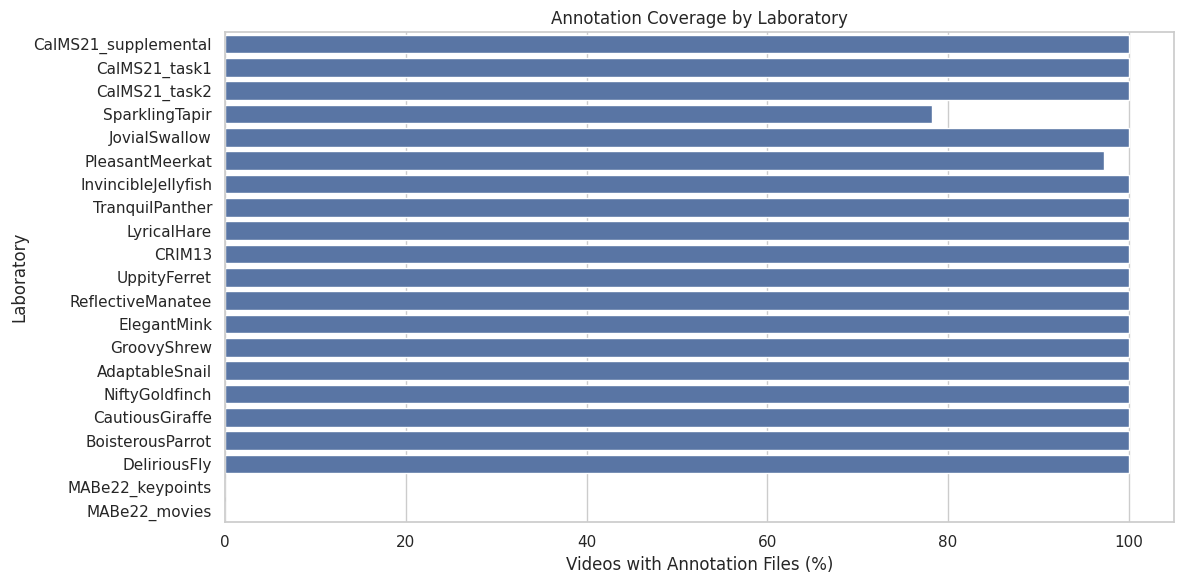

In [19]:

# Analyze annotation coverage by laboratory

annotation_labs = pd.Series(
    [path.parent.name for path in annotation_files]
)

annotation_counts = annotation_labs.value_counts()

coverage = pd.DataFrame({
    "Total Videos": train["lab_id"].value_counts(),
    "Annotated Videos": annotation_counts
}).fillna(0)

coverage["Annotated Videos"] = (
    coverage["Annotated Videos"].astype(int)
)

coverage["Coverage (%)"] = (
    coverage["Annotated Videos"]
    / coverage["Total Videos"]
    * 100
)

coverage = coverage.sort_values(
    "Annotated Videos",
    ascending=False
)

display(coverage)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=coverage["Coverage (%)"],
    y=coverage.index
)

plt.title("Annotation Coverage by Laboratory")
plt.xlabel("Videos with Annotation Files (%)")
plt.ylabel("Laboratory")
plt.tight_layout()
plt.show()


### Annotation Coverage – Findings

Annotation coverage varies substantially across the 21 data sources. CalMS21_task1, CalMS21_task2, and CalMS21_supplemental have annotation files for all their training videos.

In contrast, MABe22_keypoints and MABe22_movies contain 5,320 and 2,606 videos respectively, but neither source has annotation files in the provided training dataset.

This distinction is important for supervised learning. Videos without annotation files cannot automatically be treated as negative examples. Baseline training should therefore use videos with suitable behavior annotations, while also considering differences in behavior labeling and tracking configurations across laboratories.

## 2. Baseline Model Development

### 2.1 Selection of the Baseline Task

We first inspect the available annotations and tracking configurations in the CalMS21_task1 dataset. The goal is to select a well-defined behavior recognition task and construct a reproducible baseline using appropriately labeled videos. This focused experiment is not equivalent to the complete Kaggle competition task.

In [20]:

# Inspect CalMS21_task1 for baseline task selection

import ast
from collections import Counter

LAB = "CalMS21_task1"

lab_metadata = train[
    train["lab_id"] == LAB
].copy()

lab_annotation_files = [
    p for p in annotation_files
    if p.parent.name == LAB
]

action_counts_lab = Counter()
sample_actions = None

for path in lab_annotation_files:
    df = pd.read_parquet(
        path,
        columns=[
            "agent_id", "target_id",
            "action", "start_frame", "stop_frame"
        ]
    )

    action_counts_lab.update(
        df["action"].value_counts().to_dict()
    )

    if sample_actions is None:
        sample_actions = df.head(10).copy()

print("Laboratory:", LAB)
print("Training videos:", len(lab_metadata))
print("Annotation files:", len(lab_annotation_files))

print("\nAvailable behaviors:")
display(
    pd.DataFrame(
        action_counts_lab.items(),
        columns=["Action", "Event Count"]
    ).sort_values("Event Count", ascending=False)
)

print("\nTracked body part configurations:")
display(
    lab_metadata["body_parts_tracked"].value_counts()
)

print("\nBehavior labeling configurations:")
display(
    lab_metadata["behaviors_labeled"].value_counts()
)

print("\nExample annotation records:")
display(sample_actions)


Laboratory: CalMS21_task1
Training videos: 101
Annotation files: 101

Available behaviors:


,Action,Event Count
0,sniff,2736
3,sniffbody,1524
2,sniffgenital,1020
4,sniffface,639
6,attack,557
1,mount,481
5,approach,349
8,genitalgroom,50
7,intromit,37



Tracked body part configurations:


,count
body_parts_tracked,
"[""ear_left"", ""ear_right"", ""hip_left"", ""hip_right"", ""neck"", ""nose"", ""tail_base""]",101



Behavior labeling configurations:


,count
behaviors_labeled,
"[""mouse1,mouse2,mount"", ""mouse1,mouse2,sniff"", ""mouse1,mouse2,sniffgenital""]",11
"[""mouse1,mouse2,approach"", ""mouse1,mouse2,attack"", ""mouse1,mouse2,sniffbody"", ""mouse1,mouse2,sniffface"", ""mouse1,mouse2,sniffgenital""]",11
"[""mouse1,mouse2,approach"", ""mouse1,mouse2,mount"", ""mouse1,mouse2,sniffbody"", ""mouse1,mouse2,sniffface"", ""mouse1,mouse2,sniffgenital""]",10
"[""mouse1,mouse2,attack"", ""mouse1,mouse2,sniff""]",10
"[""mouse1,mouse2,approach"", ""mouse1,mouse2,mount"", ""mouse1,mouse2,sniffbody"", ""mouse1,mouse2,sniffface"", ""mouse1,mouse2,sniffgenital"", ""mouse1,self,genitalgroom""]",9
"[""mouse1,mouse2,sniff"", ""mouse1,mouse2,sniffgenital""]",6
"[""mouse1,mouse2,mount"", ""mouse1,mouse2,sniff""]",5
"[""mouse1,mouse2,approach"", ""mouse1,mouse2,intromit"", ""mouse1,mouse2,mount"", ""mouse1,mouse2,sniffbody"", ""mouse1,mouse2,sniffface"", ""mouse1,mouse2,sniffgenital"", ""mouse1,self,genitalgroom""]",5
"[""mouse1,mouse2,approach"", ""mouse1,mouse2,sniffbody"", ""mouse1,mouse2,sniffface"", ""mouse1,mouse2,sniffgenital""]",5



Example annotation records:


,agent_id,target_id,action,start_frame,stop_frame
0,1,2,sniffgenital,0,36
1,1,2,sniff,37,69
2,1,2,sniffgenital,70,271
3,1,2,sniff,272,337
4,1,2,sniffgenital,338,383
5,1,2,sniff,384,404
6,1,2,sniffgenital,405,506
7,1,2,sniff,507,545
8,1,2,sniff,565,571
9,1,2,sniff,647,671


### 2.2 Selecting Eligible Videos for Sniffbody Detection

We focus on the directed behavior mouse1 → mouse2: sniffbody within the CalMS21_task1 dataset.

Only videos that explicitly include this behavior in their labeling configuration will be selected. This prevents videos without relevant annotations from being incorrectly treated as negative examples.

The baseline will perform frame-level binary classification. This is a simplified experiment and does not represent the complete Kaggle competition task.

In [21]:

# Select videos explicitly labeled for sniffbody

import ast

TARGET_ACTION = "sniffbody"
TARGET_AGENT = "mouse1"
TARGET_MOUSE = "mouse2"

def has_target_behavior(value):
    if pd.isna(value):
        return False

    try:
        labels = ast.literal_eval(value)
    except (ValueError, SyntaxError):
        return False

    target = (
        f"{TARGET_AGENT},"
        f"{TARGET_MOUSE},"
        f"{TARGET_ACTION}"
    )

    return target in labels

eligible_metadata = lab_metadata[
    lab_metadata["behaviors_labeled"].apply(
        has_target_behavior
    )
].copy()

print("Total CalMS21_task1 videos:", len(lab_metadata))
print("Eligible sniffbody videos:", len(eligible_metadata))

print("\nEligible video IDs:")
display(
    eligible_metadata[
        ["lab_id", "video_id",
         "frames_per_second", "video_duration_sec"]
    ].head(10)
)


Total CalMS21_task1 videos: 101
Eligible sniffbody videos: 60

Eligible video IDs:


,lab_id,video_id,frames_per_second,video_duration_sec
343,CalMS21_task1,13638642,30.0,209.3
344,CalMS21_task1,25423023,30.0,224.9
345,CalMS21_task1,25577048,30.0,315.4
346,CalMS21_task1,25669938,30.0,60.0
347,CalMS21_task1,33033070,30.0,193.5
352,CalMS21_task1,185446354,30.0,141.5
353,CalMS21_task1,190981840,30.0,49.1
354,CalMS21_task1,208838060,30.0,79.7
355,CalMS21_task1,231670784,30.0,127.7
357,CalMS21_task1,400134184,30.0,148.2


In [22]:

# Check positive sniffbody events in eligible videos

positive_events = 0
videos_with_positive_events = 0

for _, row in eligible_metadata.iterrows():

    video_id = row["video_id"]
    lab_id = row["lab_id"]

    path = (
        data_dir
        / "train_annotation"
        / lab_id
        / f"{video_id}.parquet"
    )

    if not path.exists():
        continue

    annotations = pd.read_parquet(path)

    selected = annotations[
        (annotations["action"] == TARGET_ACTION) &
        (annotations["agent_id"].astype(str).isin(["1", "mouse1"])) &
        (annotations["target_id"].astype(str).isin(["2", "mouse2"]))
    ]

    positive_events += len(selected)

    if len(selected) > 0:
        videos_with_positive_events += 1

print("Eligible videos:", len(eligible_metadata))
print("Positive sniffbody events:", positive_events)
print("Videos containing positive events:", videos_with_positive_events)


Eligible videos: 60
Positive sniffbody events: 1524
Videos containing positive events: 60


### Baseline Task Selection – Findings

Among the 101 CalMS21_task1 videos, 60 explicitly include mouse1-to-mouse2 sniffbody in their labeling configuration. These videos contain 1,524 annotated sniffbody events, and all 60 contain at least one positive event.

The baseline experiment will use these eligible videos to construct a directed, frame-level binary classification task. This restricted setup avoids treating videos without relevant labeling coverage as negative examples.

### 2.3 Video-Level Train, Validation, and Test Split

The 60 eligible videos are divided into 42 training (70%), 9 validation (15%), and 9 independent test videos (15%) using a fixed random seed.

The split is performed at video level to prevent frames from the same recording appearing in different datasets. A larger training set is preferred due to the limited number of eligible videos. The independent test set will be reserved for final evaluation.

In [23]:


from sklearn.model_selection import train_test_split

video_ids = eligible_metadata["video_id"].tolist()

train_ids, temp_ids = train_test_split(
    video_ids,
    test_size=0.30,
    random_state=42,
    shuffle=True
)

val_ids, test_ids = train_test_split(
    temp_ids,
    test_size=0.50,
    random_state=42,
    shuffle=True
)

assert len(train_ids) == 42
assert len(val_ids) == 9
assert len(test_ids) == 9

assert not (set(train_ids) & set(val_ids))
assert not (set(train_ids) & set(test_ids))
assert not (set(val_ids) & set(test_ids))

print("Training videos:", len(train_ids))
print("Validation videos:", len(val_ids))
print("Independent test videos:", len(test_ids))
print("No video overlap between splits.")



Training videos: 42
Validation videos: 9
Independent test videos: 9
No video overlap between splits.


### 2.4 Frame-Level Label Construction

Behavior annotations are converted into binary frame-level labels using half-open intervals [start_frame, stop_frame). A positive label indicates an annotated mouse1-to-mouse2 sniffbody event. Other frames are treated as negative only for videos where this directed behavior is explicitly included in the labeling configuration.

We first validate the label construction on a single eligible video before processing the complete dataset.

In [24]:

# Construct binary frame labels for one eligible video

sample_video_id = int(train_ids[0])
sample_lab = "CalMS21_task1"

annotation_path = (
    data_dir
    / "train_annotation"
    / sample_lab
    / f"{sample_video_id}.parquet"
)

tracking_path = (
    data_dir
    / "train_tracking"
    / sample_lab
    / f"{sample_video_id}.parquet"
)

annotations = pd.read_parquet(annotation_path)
tracking = pd.read_parquet(tracking_path)

# Mouse1 -> Mouse2 sniffbody events
target_events = annotations[
    (annotations["action"] == "sniffbody") &
    (annotations["agent_id"].astype(str).isin(["1", "mouse1"])) &
    (annotations["target_id"].astype(str).isin(["2", "mouse2"]))
].copy()

# Identify available frames
frames = np.sort(
    tracking["video_frame"].unique()
)

frame_labels = pd.DataFrame({
    "video_frame": frames,
    "label": np.zeros(len(frames), dtype=np.int8)
})

# Assign positive labels using half-open intervals
for _, event in target_events.iterrows():
    start = int(event["start_frame"])
    stop = int(event["stop_frame"])

    mask = (
        (frame_labels["video_frame"] >= start) &
        (frame_labels["video_frame"] < stop)
    )

    frame_labels.loc[mask, "label"] = 1

print("Video ID:", sample_video_id)
print("Total frames:", len(frame_labels))
print("Positive events:", len(target_events))

print("Positive frames:", frame_labels["label"].sum())
print("Negative frames:", (frame_labels["label"] == 0).sum())

print("Positive frame ratio:",
      round(frame_labels["label"].mean() * 100, 2), "%")

display(frame_labels.head(15))


Video ID: 1380404564
Total frames: 3919
Positive events: 17
Positive frames: 264
Negative frames: 3655
Positive frame ratio: 6.74 %


,video_frame,label
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0
5,5,0
6,6,0
7,7,0
8,8,0
9,9,0


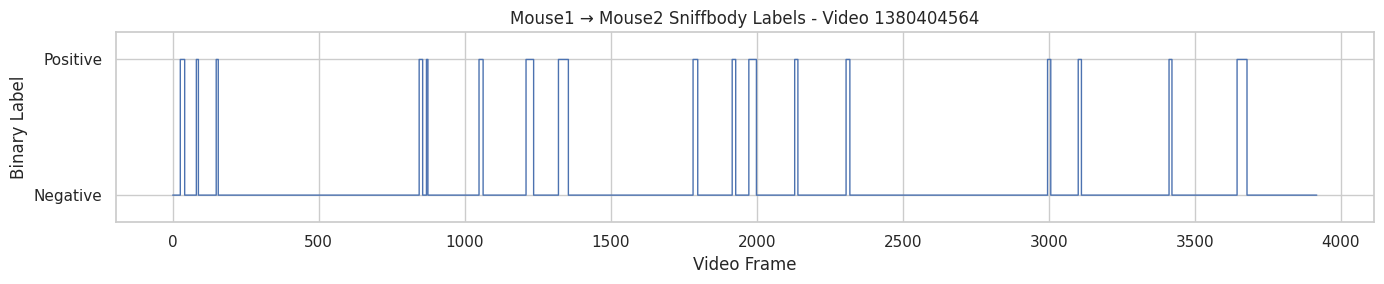

In [25]:

# Visualize binary sniffbody labels

plt.figure(figsize=(14, 3))

plt.step(
    frame_labels["video_frame"],
    frame_labels["label"],
    where="post",
    linewidth=1
)

plt.title(
    f"Mouse1 → Mouse2 Sniffbody Labels - Video {sample_video_id}"
)

plt.xlabel("Video Frame")
plt.ylabel("Binary Label")

plt.yticks([0, 1], ["Negative", "Positive"])
plt.ylim(-0.2, 1.2)

plt.tight_layout()
plt.show()


### Frame-Level Labeling – Findings

The selected video (1380404564) contains 3,919 frames and 17 annotated mouse1-to-mouse2 sniffbody events.

After converting the annotated intervals into binary labels, 264 frames (6.74%) were labeled positive and 3,655 frames (93.26%) were labeled negative.

This demonstrates substantial class imbalance at frame level. A model that predicts only the negative class could achieve high accuracy while failing to identify sniffbody behavior. Therefore, precision, recall, and F1-score will be used to evaluate baseline performance.

### 2.5 Feature Extraction from Tracking Coordinates

Raw tracking data contains the X and Y coordinates of different body parts for each mouse and video frame. We transform these coordinates into numerical features that may help distinguish sniffbody behavior from non-sniffbody frames.

The initial features include inter-mouse distances, individual movement speeds, and changes in relative position. Pixel-based measurements will be normalized using the approximate pixels-per-centimeter metadata where appropriate.

In [26]:
# Extract numerical features from one video

def extract_features(tracking_df, pixels_per_cm, fps):

    if pixels_per_cm <= 0 or fps <= 0:
        raise ValueError("FPS and pixels_per_cm must be positive.")

    selected_parts = ["nose", "neck", "tail_base"]

    subset = tracking_df[
        tracking_df["bodypart"].isin(selected_parts) &
        tracking_df["mouse_id"].isin([1, 2])
    ].copy()

    # Treat (0, 0) points as invalid tracking measurements
    invalid = (subset["x"] == 0) & (subset["y"] == 0)
    subset.loc[invalid, ["x", "y"]] = np.nan

    positions = subset.pivot(
        index="video_frame",
        columns=["mouse_id", "bodypart"],
        values=["x", "y"]
    ).sort_index()

    # Keep frames even if all selected points are missing
    positions = positions.reindex(
        np.sort(tracking_df["video_frame"].unique())
    )

    def point(mouse, part):
        return (
            positions[("x", mouse, part)],
            positions[("y", mouse, part)]
        )

    def distance(p1, p2):
        return np.sqrt(
            (p1[0] - p2[0])**2 +
            (p1[1] - p2[1])**2
        ) / pixels_per_cm

    m1_nose = point(1, "nose")
    m1_neck = point(1, "neck")

    m2_nose = point(2, "nose")
    m2_neck = point(2, "neck")
    m2_tail = point(2, "tail_base")

    features = pd.DataFrame(index=positions.index)

    features["nose_to_neck_cm"] = distance(
        m1_nose, m2_neck
    )

    features["nose_to_nose_cm"] = distance(
        m1_nose, m2_nose
    )

    features["nose_to_tail_cm"] = distance(
        m1_nose, m2_tail
    )

    features["neck_to_neck_cm"] = distance(
        m1_neck, m2_neck
    )

    frame_delta = pd.Series(
        positions.index,
        index=positions.index
    ).diff()

    for mouse in [1, 2]:
        x, y = point(mouse, "nose")

        displacement = np.sqrt(
            x.diff()**2 + y.diff()**2
        )

        features[f"mouse{mouse}_speed"] = (
            displacement * fps /
            (pixels_per_cm * frame_delta)
        )

    features["distance_change"] = (
        features["nose_to_neck_cm"].diff() /
        frame_delta
    )

    return features.replace(
        [np.inf, -np.inf], np.nan
    )



# Obtain video metadata
sample_metadata = eligible_metadata[
    eligible_metadata["video_id"] == sample_video_id
].iloc[0]

pixels_per_cm = sample_metadata["pix_per_cm_approx"]
fps = sample_metadata["frames_per_second"]

# Extract features for our sample video
sample_features = extract_features(
    tracking,
    pixels_per_cm,
    fps
)

print("Feature table shape:", sample_features.shape)
print("\nFeature columns:")
print(sample_features.columns.tolist())

display(sample_features.head(10))

print("\nMissing values:")
print(sample_features.isnull().sum())


Feature table shape: (3919, 7)

Feature columns:
['nose_to_neck_cm', 'nose_to_nose_cm', 'nose_to_tail_cm', 'neck_to_neck_cm', 'mouse1_speed', 'mouse2_speed', 'distance_change']


,nose_to_neck_cm,nose_to_nose_cm,nose_to_tail_cm,neck_to_neck_cm,mouse1_speed,mouse2_speed,distance_change
video_frame,,,,,,,
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:
nose_to_neck_cm    525
nose_to_nose_cm    525
nose_to_tail_cm    525
neck_to_neck_cm    525
mouse1_speed       526
mouse2_speed       526
distance_change    526
dtype: int64


### 2.6 Handling Invalid Tracking Coordinates

Initial feature validation revealed zero-valued tracking coordinates and unusually large movement speeds. These observations suggest that some coordinate records may represent tracking failures rather than actual mouse positions.

For the selected CalMS21_task1 data, body points with both X and Y coordinates equal to zero are treated as invalid. These values are converted to missing measurements before calculating distances and movement speeds.

In the examined video, this preprocessing resulted in 3,393 usable frames out of 3,919. Frames with incomplete features will be excluded from the baseline training dataset.

In [27]:

# Validate corrected features

print("FEATURE STATISTICS")
display(
    sample_features.describe().T[
        ["min", "mean", "50%", "max", "std"]
    ]
)

print("\nMISSING VALUES")
print(sample_features.isna().sum())

valid_features = sample_features.dropna()

print("\nTotal frames:", len(sample_features))
print("Valid frames:", len(valid_features))
print("Removed frames:",
      len(sample_features) - len(valid_features))

print("\nMAXIMUM SPEEDS")
print(
    valid_features[
        ["mouse1_speed", "mouse2_speed"]
    ].max()
)


FEATURE STATISTICS


,min,mean,50%,max,std
nose_to_neck_cm,0.111542,14.621868,11.665757,42.505581,11.671257
nose_to_nose_cm,0.023757,14.392618,10.698092,44.403168,11.267593
nose_to_tail_cm,0.143070,16.849243,13.616512,46.740055,12.225078
neck_to_neck_cm,0.007486,14.414563,9.845285,41.784386,11.873100
mouse1_speed,0.144434,16.237810,12.014059,153.815338,14.825255
mouse2_speed,0.000000,15.080986,7.544837,300.585297,26.827368
distance_change,-4.930801,0.010645,0.011725,3.992739,0.619021



MISSING VALUES
nose_to_neck_cm    525
nose_to_nose_cm    525
nose_to_tail_cm    525
neck_to_neck_cm    525
mouse1_speed       526
mouse2_speed       526
distance_change    526
dtype: int64

Total frames: 3919
Valid frames: 3393
Removed frames: 526

MAXIMUM SPEEDS
mouse1_speed    153.815338
mouse2_speed    300.585297
dtype: float32


### 2.7 Feature Validation

Before training baseline models, we validate the extracted features by checking their distributions and inspecting the underlying tracking coordinates. This helps identify potentially invalid or uninformative measurements.

In [28]:

# Validate extracted features and raw coordinates

print("FEATURE STATISTICS")
display(
    sample_features.describe().T[
        ["min", "mean", "50%", "max", "std"]
    ]
)

print("\nNON-ZERO FEATURE COUNTS")
print((sample_features.fillna(0) != 0).sum())

print("\nRAW TRACKING COORDINATES")
raw_sample = tracking[
    (tracking["bodypart"].isin(["nose", "neck"])) &
    (tracking["mouse_id"].isin([1, 2]))
]

display(
    raw_sample[
        ["video_frame", "mouse_id", "bodypart", "x", "y"]
    ].head(20)
)

print("\nPIXELS PER CM:", pixels_per_cm)
print("FPS:", fps)

print("\nMOUSE IDS:", tracking["mouse_id"].unique())
print("BODY PARTS:", tracking["bodypart"].unique())


FEATURE STATISTICS


,min,mean,50%,max,std
nose_to_neck_cm,0.111542,14.621868,11.665757,42.505581,11.671257
nose_to_nose_cm,0.023757,14.392618,10.698092,44.403168,11.267593
nose_to_tail_cm,0.143070,16.849243,13.616512,46.740055,12.225078
neck_to_neck_cm,0.007486,14.414563,9.845285,41.784386,11.873100
mouse1_speed,0.144434,16.237810,12.014059,153.815338,14.825255
mouse2_speed,0.000000,15.080986,7.544837,300.585297,26.827368
distance_change,-4.930801,0.010645,0.011725,3.992739,0.619021



NON-ZERO FEATURE COUNTS
nose_to_neck_cm    3394
nose_to_nose_cm    3394
nose_to_tail_cm    3394
neck_to_neck_cm    3394
mouse1_speed       3393
mouse2_speed       3387
distance_change    3393
dtype: int64

RAW TRACKING COORDINATES


,video_frame,mouse_id,bodypart,x,y
4,0,1,neck,0.0,0.0
5,0,1,nose,0.0,0.0
11,0,2,neck,0.0,0.0
12,0,2,nose,0.0,0.0
18,1,1,neck,0.0,0.0
19,1,1,nose,0.0,0.0
25,1,2,neck,0.0,0.0
26,1,2,nose,0.0,0.0
32,2,1,neck,0.0,0.0
33,2,1,nose,0.0,0.0



PIXELS PER CM: 18.33
FPS: 30.0

MOUSE IDS: [1 2]
BODY PARTS: ['ear_left' 'ear_right' 'hip_left' 'hip_right' 'neck' 'nose' 'tail_base']


### 2.8 Motion Feature Quality Control

After treating zero-valued coordinates as invalid measurements, 3,393 of the 3,919 frames remained usable in the sample video.

Although preprocessing reduced the largest calculated speeds, some unusually high values remain. These may result from abrupt movements or errors in pose tracking.

We examine the speed distributions and extreme values before deciding whether additional preprocessing is necessary.


mouse1_speed
Median: 12.01
95th percentile: 43.97
99th percentile: 66.59
Maximum: 153.82
Frames above 100 cm/s: 10

mouse2_speed
Median: 7.54
95th percentile: 46.58
99th percentile: 165.48
Maximum: 300.59
Frames above 100 cm/s: 63


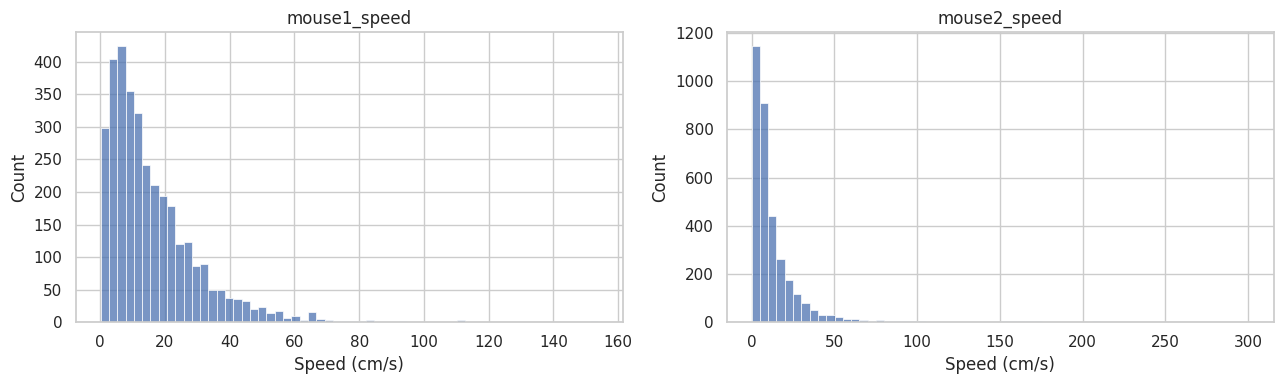

In [29]:

# Analyze extreme movement speeds

speed_columns = ["mouse1_speed", "mouse2_speed"]

for col in speed_columns:
    speeds = valid_features[col]

    print(f"\n{col}")
    print("Median:", round(speeds.median(), 2))
    print("95th percentile:", round(speeds.quantile(0.95), 2))
    print("99th percentile:", round(speeds.quantile(0.99), 2))
    print("Maximum:", round(speeds.max(), 2))
    print("Frames above 100 cm/s:",
          int((speeds > 100).sum()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, col in zip(axes, speed_columns):
    sns.histplot(
        valid_features[col],
        bins=60,
        ax=ax
    )
    ax.set_title(col)
    ax.set_xlabel("Speed (cm/s)")

plt.tight_layout()
plt.show()


### Motion Feature Quality Control – Findings

The speed distributions are right-skewed, with most observations concentrated at relatively low speeds. Mouse 1 has a median speed of 12.01 cm/s, while Mouse 2 has a median speed of 7.54 cm/s.

However, 10 valid frames for Mouse 1 and 63 for Mouse 2 exceed 100 cm/s. These extreme values may reflect rapid movements or tracking inaccuracies.

For the initial baseline, we retain these measurements rather than introducing an arbitrary speed threshold. Frames with incomplete features will be excluded, and the potential influence of extreme values will be considered during model evaluation.

### 2.9 Building the Baseline Dataset

We apply the validated feature extraction and binary labeling procedures to all 60 eligible CalMS21_task1 videos.

Each video is processed independently. Tracking features are aligned with their corresponding annotation labels using video frame numbers. Rows with incomplete numerical features are excluded.

The previously defined video-level split is preserved to prevent frames from the same recording appearing in multiple datasets. The resulting feature tables will be used for baseline model training and evaluation.

In [30]:

# Build a frame-level dataset from selected videos

def process_video(video_id):
    video_id = int(video_id)
    lab = "CalMS21_task1"

    row = eligible_metadata[
        eligible_metadata["video_id"] == video_id
    ].iloc[0]

    tracking_path = (
        data_dir / "train_tracking" /
        lab / f"{video_id}.parquet"
    )

    annotation_path = (
        data_dir / "train_annotation" /
        lab / f"{video_id}.parquet"
    )

    tracking_df = pd.read_parquet(tracking_path)
    annotations_df = pd.read_parquet(annotation_path)

    features = extract_features(
        tracking_df,
        row["pix_per_cm_approx"],
        row["frames_per_second"]
    )

    # Align labels with actual frame numbers
    frames = features.index.to_numpy()
    labels = np.zeros(len(frames), dtype=np.int8)

    events = annotations_df[
        (annotations_df["action"] == "sniffbody") &
        (annotations_df["agent_id"] == 1) &
        (annotations_df["target_id"] == 2)
    ]

    for event in events.itertuples():
        labels[
            (frames >= event.start_frame) &
            (frames < event.stop_frame)
        ] = 1

    result = features.copy()
    result["label"] = labels
    result["video_id"] = video_id

    # Remove incomplete feature rows
    result = result.dropna(
        subset=features.columns
    )

    return result.reset_index()


def build_split(video_ids, split_name):
    parts = []

    for i, video_id in enumerate(video_ids, 1):
        part = process_video(video_id)
        parts.append(part)

        if i % 10 == 0 or i == len(video_ids):
            print(
                f"{split_name}: "
                f"{i}/{len(video_ids)} videos processed"
            )

    dataset = pd.concat(parts, ignore_index=True)

    print(f"\n{split_name} completed")
    print("Total valid frames:", len(dataset))
    print("Positive frames:", int(dataset["label"].sum()))
    print("Negative frames:",
          int((dataset["label"] == 0).sum()))
    print("Positive ratio:",
          round(dataset["label"].mean() * 100, 2), "%")

    return dataset


In [31]:

# Build training dataset (42 videos)

train_dataset = build_split(
    train_ids,
    "Training"
)

print("\nTraining dataset shape:")
print(train_dataset.shape)

display(train_dataset.head())

assert train_dataset["video_id"].nunique() == 42


Training: 10/42 videos processed
Training: 20/42 videos processed
Training: 30/42 videos processed
Training: 40/42 videos processed
Training: 42/42 videos processed

Training completed
Total valid frames: 242132
Positive frames: 30143
Negative frames: 211989
Positive ratio: 12.45 %

Training dataset shape:
(242132, 10)


,video_frame,nose_to_neck_cm,nose_to_nose_cm,nose_to_tail_cm,neck_to_neck_cm,mouse1_speed,mouse2_speed,distance_change,label,video_id
0,347,4.463776,8.756573,3.560946,3.804245,6.683433,32.786678,0.340154,0,1380404564
1,348,4.662942,8.972250,3.702045,3.886918,0.860690,11.194300,0.199167,0,1380404564
2,349,4.558062,8.614676,3.862549,3.956005,7.451060,3.780194,-0.104881,0,1380404564
3,350,4.135818,8.233219,3.664480,3.670447,8.248093,9.896327,-0.422244,0,1380404564
4,351,3.923949,7.480672,4.015117,3.144399,4.857392,23.627314,-0.211869,0,1380404564


### 2.10 Validation and Test Dataset Preparation

The training split contains 242,132 valid frames from 42 videos, including 30,143 positive sniffbody frames (12.45%). The distribution indicates class imbalance, which will be considered during baseline model evaluation.

We now process the nine validation videos and nine independent test videos using the same feature extraction and annotation alignment procedures. The test set is reserved for final evaluation and will not be used for model selection.

In [32]:

# Build validation and independent test datasets

val_dataset = build_split(
    val_ids,
    "Validation"
)

test_dataset = build_split(
    test_ids,
    "Independent Test"
)

print("\nDATASET SUMMARY")

for name, dataset in [
    ("Training", train_dataset),
    ("Validation", val_dataset),
    ("Test", test_dataset)
]:
    print(
        f"{name}: "
        f"{dataset['video_id'].nunique()} videos, "
        f"{len(dataset):,} valid frames, "
        f"{dataset['label'].mean() * 100:.2f}% positive"
    )

# Verify video-level separation
assert set(train_dataset.video_id).isdisjoint(
    set(val_dataset.video_id)
)

assert set(train_dataset.video_id).isdisjoint(
    set(test_dataset.video_id)
)

assert set(val_dataset.video_id).isdisjoint(
    set(test_dataset.video_id)
)

print("\nNo video leakage between splits.")


Validation: 9/9 videos processed

Validation completed
Total valid frames: 41451
Positive frames: 5681
Negative frames: 35770
Positive ratio: 13.71 %
Independent Test: 9/9 videos processed

Independent Test completed
Total valid frames: 54192
Positive frames: 7399
Negative frames: 46793
Positive ratio: 13.65 %

DATASET SUMMARY
Training: 42 videos, 242,132 valid frames, 12.45% positive
Validation: 9 videos, 41,451 valid frames, 13.71% positive
Test: 9 videos, 54,192 valid frames, 13.65% positive

No video leakage between splits.


### 2.11 Baseline Model Training

We train two baseline classifiers for frame-level sniffbody detection: a Dummy Classifier and a Random Forest Classifier.

The Dummy Classifier always predicts the most frequent training class and provides a reference for model performance. The Random Forest uses seven numerical features extracted from mouse tracking coordinates.

Models are trained only on the training set and evaluated on the validation set. The independent test set remains untouched during model selection.

Due to class imbalance, precision, recall, F1-score, and average precision are used alongside accuracy.

In [33]:

# Prepare features and labels for baseline training

FEATURE_COLUMNS = [
    "nose_to_neck_cm",
    "nose_to_nose_cm",
    "nose_to_tail_cm",
    "neck_to_neck_cm",
    "mouse1_speed",
    "mouse2_speed",
    "distance_change"
]

X_train = train_dataset[FEATURE_COLUMNS]
y_train = train_dataset["label"]

X_val = val_dataset[FEATURE_COLUMNS]
y_val = val_dataset["label"]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nMissing training values:", X_train.isna().sum().sum())
print("Missing validation values:", X_val.isna().sum().sum())

assert X_train.isna().sum().sum() == 0
assert X_val.isna().sum().sum() == 0
assert y_train.nunique() == 2

print("\nFeature preparation completed.")


Training features: (242132, 7)
Validation features: (41451, 7)

Training class distribution:
label
0    211989
1     30143
Name: count, dtype: int64

Missing training values: 0
Missing validation values: 0

Feature preparation completed.


In [34]:

# Baseline 1: Dummy Classifier

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_val)
dummy_probabilities = dummy_model.predict_proba(X_val)[:, 1]

print("DUMMY CLASSIFIER - VALIDATION RESULTS")

print("Accuracy:",
      round(accuracy_score(y_val, dummy_predictions), 4))

print("Precision:",
      round(precision_score(
          y_val, dummy_predictions, zero_division=0
      ), 4))

print("Recall:",
      round(recall_score(
          y_val, dummy_predictions, zero_division=0
      ), 4))

print("F1-score:",
      round(f1_score(
          y_val, dummy_predictions, zero_division=0
      ), 4))

print("Average Precision:",
      round(average_precision_score(
          y_val, dummy_probabilities
      ), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, dummy_predictions))


DUMMY CLASSIFIER - VALIDATION RESULTS
Accuracy: 0.8629
Precision: 0.0
Recall: 0.0
F1-score: 0.0
Average Precision: 0.1371

Confusion Matrix:
[[35770     0]
 [ 5681     0]]


In [35]:

# Baseline 2: Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=80,
    max_depth=12,
    min_samples_leaf=20,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_val)
rf_probabilities = rf_model.predict_proba(X_val)[:, 1]

print("RANDOM FOREST - VALIDATION RESULTS")

print("Accuracy:",
      round(accuracy_score(y_val, rf_predictions), 4))

print("Precision:",
      round(precision_score(
          y_val, rf_predictions, zero_division=0
      ), 4))

print("Recall:",
      round(recall_score(
          y_val, rf_predictions, zero_division=0
      ), 4))

print("F1-score:",
      round(f1_score(
          y_val, rf_predictions, zero_division=0
      ), 4))

print("Average Precision:",
      round(average_precision_score(
          y_val, rf_probabilities
      ), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, rf_predictions))


RANDOM FOREST - VALIDATION RESULTS
Accuracy: 0.7531
Precision: 0.3371
Recall: 0.8289
F1-score: 0.4793
Average Precision: 0.3976

Confusion Matrix:
[[26509  9261]
 [  972  4709]]


### Baseline Training – Findings

Two baseline classifiers were trained using 242,132 valid training frames and evaluated on 41,451 validation frames.

The Dummy Classifier achieved 86.29% accuracy but an F1-score of 0 because it predicted only the majority negative class.

The Random Forest achieved an F1-score of 0.4793, recall of 0.8289, precision of 0.3371, and average precision of 0.3976.

These results demonstrate that the Random Forest captures meaningful patterns associated with sniffbody behavior, although its relatively low precision indicates a substantial number of false-positive predictions. Further evaluation and threshold selection are needed before assessing performance on the independent test set.

## 3. Model Evaluation and Comparison

### 3.1 Baseline Model Comparison

The Dummy Classifier and Random Forest are evaluated on the same validation dataset containing 41,451 frames from nine independent videos.

Although the Dummy Classifier achieves higher accuracy, it fails to detect any positive sniffbody frames. The Random Forest achieves substantially better F1-score and average precision, demonstrating the limitations of accuracy as a performance metric for imbalanced behavior recognition tasks.

The following analysis compares both models and examines their precision-recall trade-offs before final testing.

,Model,Accuracy,Precision,Recall,F1-score,Average Precision
0,Dummy Classifier,0.8629,0.0000,0.0000,0.0000,0.1371
1,Random Forest,0.7531,0.3371,0.8289,0.4793,0.3976


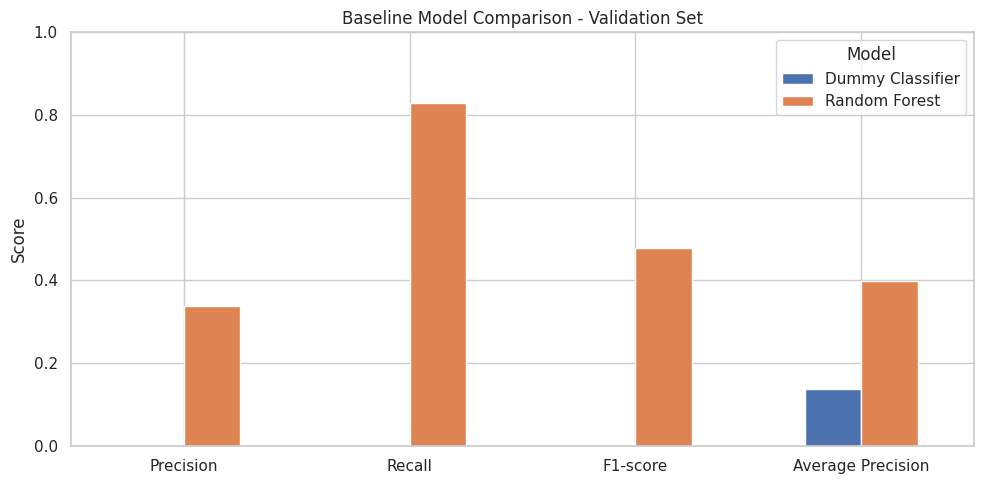

In [36]:

# Compare baseline validation performance

comparison = pd.DataFrame([
    {
        "Model": "Dummy Classifier",
        "Accuracy": accuracy_score(y_val, dummy_predictions),
        "Precision": precision_score(y_val, dummy_predictions, zero_division=0),
        "Recall": recall_score(y_val, dummy_predictions, zero_division=0),
        "F1-score": f1_score(y_val, dummy_predictions, zero_division=0),
        "Average Precision": average_precision_score(
            y_val, dummy_probabilities
        )
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_val, rf_predictions),
        "Precision": precision_score(y_val, rf_predictions, zero_division=0),
        "Recall": recall_score(y_val, rf_predictions, zero_division=0),
        "F1-score": f1_score(y_val, rf_predictions, zero_division=0),
        "Average Precision": average_precision_score(
            y_val, rf_probabilities
        )
    }
])

display(comparison.round(4))

# Visualize key performance metrics
metrics_to_plot = [
    "Precision", "Recall", "F1-score", "Average Precision"
]

comparison.set_index("Model")[metrics_to_plot].T.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

plt.title("Baseline Model Comparison - Validation Set")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()
plt.show()


### 3.2 Precision-Recall Analysis

We examine the precision-recall curve of the Random Forest using validation predictions. Because positive sniffbody frames are less frequent than negative frames, precision-recall analysis provides a more informative view of detection performance than accuracy alone.

The curve illustrates how changing the decision threshold affects the trade-off between detecting positive events and reducing false-positive predictions.

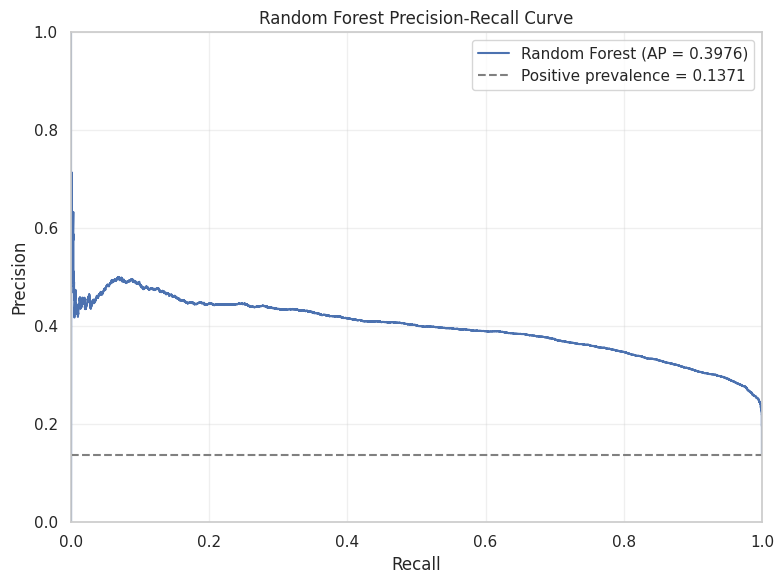

In [38]:

# Precision-recall curve for Random Forest

from sklearn.metrics import precision_recall_curve

precision_values, recall_values, thresholds = (
    precision_recall_curve(y_val, rf_probabilities)
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"Random Forest (AP = {average_precision_score(y_val, rf_probabilities):.4f})"
)

plt.axhline(
    y=y_val.mean(),
    linestyle="--",
    color="gray",
    label=f"Positive prevalence = {y_val.mean():.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest Precision-Recall Curve")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Baseline Comparison and Precision-Recall Findings

The Random Forest outperforms the Dummy Classifier in F1-score and average precision, although the Dummy Classifier achieves higher accuracy by predicting only the majority class.

The Random Forest achieves an average precision of 0.3976, compared with a positive class prevalence of 0.1371 in the validation set. Its precision-recall curve remains substantially above this reference level across most recall values.

These findings indicate that the model can distinguish positive sniffbody frames to some extent, but the trade-off between precision and recall requires further investigation.

### 3.3 Decision Threshold Optimization

The Random Forest initially classifies frames using a probability threshold of 0.50. We examine alternative thresholds on the validation set to identify a better balance between precision and recall.

The threshold that maximizes validation F1-score is selected for final evaluation. The independent test set is not used during threshold selection, preventing test-set information from influencing this decision.

Default threshold: 0.50
Default F1-score: 0.4793

Optimal validation threshold: 0.5896
Optimized F1-score: 0.4883
Optimized Precision: 0.3625
Optimized Recall: 0.7481


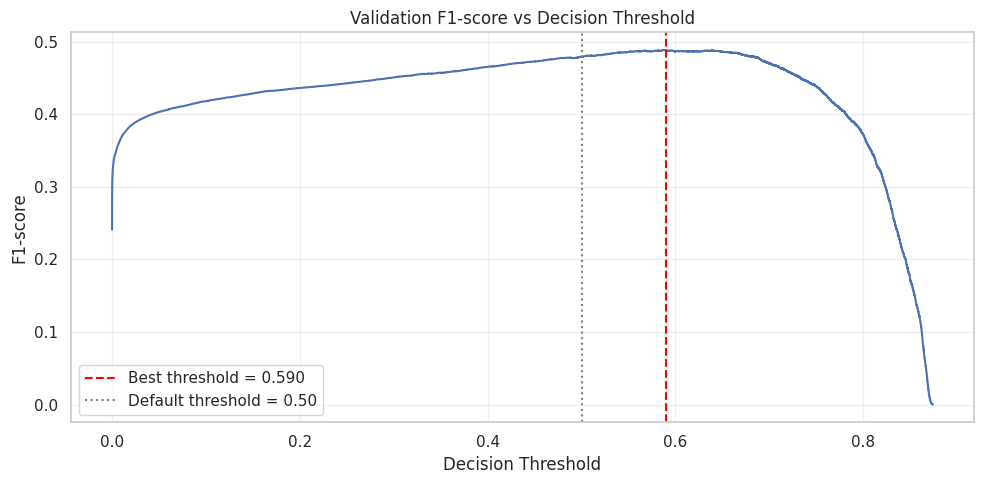

In [39]:

# Optimize the Random Forest decision threshold
# using validation data only

from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val, rf_probabilities
)

# The last precision/recall pair has no threshold
precision_t = precision[:-1]
recall_t = recall[:-1]

f1_values = (
    2 * precision_t * recall_t /
    (precision_t + recall_t + 1e-12)
)

best_index = np.argmax(f1_values)
best_threshold = float(thresholds[best_index])

optimized_predictions = (
    rf_probabilities >= best_threshold
).astype(int)

default_f1 = f1_score(y_val, rf_predictions)
optimized_f1 = f1_score(
    y_val, optimized_predictions
)

print("Default threshold: 0.50")
print("Default F1-score:", round(default_f1, 4))

print("\nOptimal validation threshold:",
      round(best_threshold, 4))

print("Optimized F1-score:",
      round(optimized_f1, 4))

print("Optimized Precision:",
      round(precision_score(
          y_val, optimized_predictions
      ), 4))

print("Optimized Recall:",
      round(recall_score(
          y_val, optimized_predictions
      ), 4))

# Visualize F1-score across thresholds

plt.figure(figsize=(10, 5))

plt.plot(thresholds, f1_values)

plt.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Best threshold = {best_threshold:.3f}"
)

plt.axvline(
    0.5,
    color="gray",
    linestyle=":",
    label="Default threshold = 0.50"
)

plt.title("Validation F1-score vs Decision Threshold")
plt.xlabel("Decision Threshold")
plt.ylabel("F1-score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Decision Threshold Optimization – Findings

The default decision threshold of 0.50 produced a validation F1-score of 0.4793. Optimizing the threshold using validation data increased the F1-score to 0.4883 at a threshold of approximately 0.5896.

Precision improved from 0.3371 to 0.3625, while recall decreased from 0.8289 to 0.7481. This reflects a trade-off between reducing false-positive predictions and detecting positive sniffbody frames.

The improvement is modest and does not establish statistical significance. The selected threshold will be fixed before evaluation on the independent test set.

### 3.4 Feature Importance Analysis

We examine the feature importance values of the trained Random Forest classifier to identify which tracking-derived measurements contribute most to its predictions.

Feature importance is calculated using the model's impurity-based importance scores. These values describe how strongly features contribute to the model's decision-tree splits, but they do not necessarily indicate causal relationships or independent predictive effects.

RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance
0,nose_to_tail_cm,0.3338
1,nose_to_neck_cm,0.2700
2,nose_to_nose_cm,0.1921
3,neck_to_neck_cm,0.1316
4,mouse1_speed,0.0284
5,mouse2_speed,0.0247
6,distance_change,0.0194


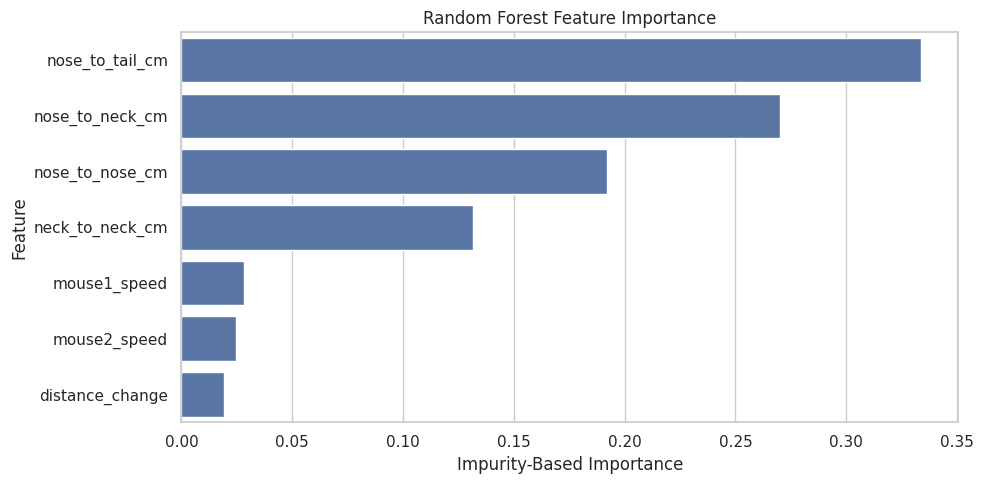


Total importance: 1.0


In [40]:

# Analyze Random Forest feature importance

feature_importance = pd.DataFrame({
    "Feature": FEATURE_COLUMNS,
    "Importance": rf_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print("RANDOM FOREST FEATURE IMPORTANCE")
display(feature_importance.round(4))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Impurity-Based Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

print(
    "\nTotal importance:",
    round(feature_importance["Importance"].sum(), 4)
)


### Feature Importance – Findings

The Random Forest relies primarily on spatial distance features. The most important feature is nose-to-tail distance (33.38%), followed by nose-to-neck distance (27.00%), nose-to-nose distance (19.21%), and neck-to-neck distance (13.16%).

Together, these four distance features account for approximately 92.75% of the model's impurity-based feature importance. Movement speeds and distance changes contribute much less.

These results suggest that relative mouse positions are particularly informative for the selected sniffbody classification task. However, impurity-based importance values do not establish causal relationships and may be influenced by correlations between features.

### 3.5 Independent Test Evaluation

After selecting the Random Forest model and its decision threshold using validation data, we evaluate the fixed model on nine independent test videos.

The test set has not been used for model training, hyperparameter selection, or threshold optimization. We report accuracy, precision, recall, F1-score, average precision, and the confusion matrix.

This evaluation measures frame-level binary sniffbody detection within the selected CalMS21_task1 subset. It does not represent the official Kaggle competition score.

In [41]:

# Independent test evaluation
# The model and threshold are fixed using validation data

X_test = test_dataset[FEATURE_COLUMNS]
y_test = test_dataset["label"]

assert X_test.isna().sum().sum() == 0
assert set(test_dataset["video_id"]).isdisjoint(
    set(train_dataset["video_id"])
)
assert set(test_dataset["video_id"]).isdisjoint(
    set(val_dataset["video_id"])
)

# Random Forest probabilities on unseen test videos
test_probabilities = rf_model.predict_proba(X_test)[:, 1]

# Apply validation-selected threshold without modification
test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

test_results = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "Average Precision": average_precision_score(
        y_test, test_probabilities
    )
}

print("INDEPENDENT TEST RESULTS")
print("Test videos:", test_dataset["video_id"].nunique())
print("Test frames:", len(X_test))
print("Fixed threshold:", round(best_threshold, 4))

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

test_cm = confusion_matrix(
    y_test, test_predictions, labels=[0, 1]
)

print("\nConfusion Matrix:")
print(test_cm)


INDEPENDENT TEST RESULTS
Test videos: 9
Test frames: 54192
Fixed threshold: 0.5896
Accuracy: 0.7918
Precision: 0.3707
Recall: 0.7520
F1-score: 0.4966
Average Precision: 0.4403

Confusion Matrix:
[[37347  9446]
 [ 1835  5564]]


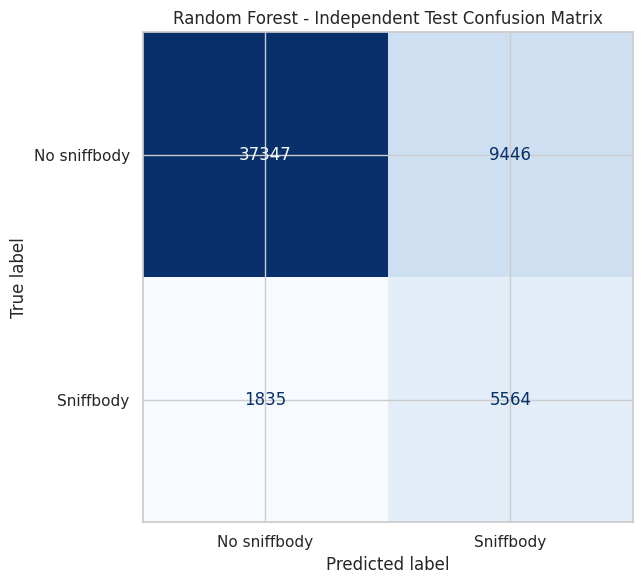

In [42]:

# Visualize independent test confusion matrix

from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["No sniffbody", "Sniffbody"]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Random Forest - Independent Test Confusion Matrix")
plt.tight_layout()
plt.show()


### Independent Test Evaluation – Findings

The Random Forest was evaluated on 54,192 valid frames from nine independent test videos using the validation-selected decision threshold of 0.5896.

The model achieved an accuracy of 0.7918, precision of 0.3707, recall of 0.7520, F1-score of 0.4966, and average precision of 0.4403.

The confusion matrix shows 37,347 true negatives, 9,446 false positives, 1,835 false negatives, and 5,564 true positives. The model successfully detects a substantial proportion of positive sniffbody frames, but still produces many false-positive predictions.

The test F1-score is close to the optimized validation F1-score of 0.4883, suggesting reasonably consistent performance across the two video splits. However, the evaluation is limited to nine test videos, and frame-level observations are correlated within recordings.

These results represent a focused binary classification baseline rather than the official Kaggle competition metric. Future work may explore richer temporal features, improved motion representations, and more advanced classification approaches.